In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import csv
import os
import yaml
import sys
from numpy import random
import torch



plt.rcParams.update({
    'font.size': 16,          # Increase overall font size
    'font.weight': 'bold',    # Make all fonts bold
    'axes.labelweight': 'bold', # Bold axis labels
    'axes.titlesize': 18,     # Bigger title font size
    'axes.titleweight': 'bold', # Bold titles
    'xtick.labelsize': 14,    # X-axis tick label size
    'ytick.labelsize': 14,    # Y-axis tick label size
    'legend.fontsize': 14,    # Legend font size
    #'legend.fontweight': 'bold',  # Bold legend text
    'figure.titlesize': 20,   # Figure title size
    'figure.titleweight': 'bold'  # Bold figure titles
})


In [18]:
def set_seed(seed: int = 42):
    """Sets seeds for reproducibility across different libraries."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed) # For multi-GPU setups
    
    # Optional: For deterministic CUDA operations
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    
    # Optional: For hash-based randomness
    os.environ['PYTHONHASHSEED'] = str(seed)

# Call the function to set the desired seed
set_seed(42) 

In [19]:
with open('C:/02_AtmPhy_ML/S4_AQ_PINN/config.yaml', 'r') as file:
    config = yaml.safe_load(file)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [20]:
# Add the repo root folder to Python path
repo_root = os.path.abspath('..')  # adjust if notebook is inside notebooks/
sys.path.append(repo_root)

Step 1: Load Data

In [21]:
from utils.data_loader import AirQualityDataset, get_data_loaders

batch_size = config['training']['batch_size']
train_loader, test_loader = get_data_loaders(config, batch_size=batch_size)

In [22]:
# Get first batch
for X_batch, y_batch in train_loader:
    print("X_batch shape:", X_batch.shape)  # (batch_size, seq_len, input_size)
    print("y_batch shape:", y_batch.shape)  # (batch_size, output_size)
    break


X_batch shape: torch.Size([32, 3, 6])
y_batch shape: torch.Size([32, 3])


In [23]:
"""
#Checks if data_loader.py is working correctly
# Get first batch from train_loader
X_batch, y_batch = next(iter(train_loader))

print("X_batch shape:", X_batch.shape)  # (batch_size, seq_len, input_size)
print("y_batch shape:", y_batch.shape)  # (batch_size, output_size)

# Print the actual values for the first few sequences
print("\nFirst 3 input sequences (X):\n", X_batch[:3])
print("\nFirst 3 target outputs (y):\n", y_batch[:3])
"""

'\n#Checks if data_loader.py is working correctly\n# Get first batch from train_loader\nX_batch, y_batch = next(iter(train_loader))\n\nprint("X_batch shape:", X_batch.shape)  # (batch_size, seq_len, input_size)\nprint("y_batch shape:", y_batch.shape)  # (batch_size, output_size)\n\n# Print the actual values for the first few sequences\nprint("\nFirst 3 input sequences (X):\n", X_batch[:3])\nprint("\nFirst 3 target outputs (y):\n", y_batch[:3])\n'

Step 2: Initialize and load the model

In [24]:
from models.lstm import LSTMRegressor

input_size = config['model']['lstm']['input_size']
output_size = config['model']['lstm']['output_size']
hidden_size = config['model']['lstm']['hidden_size']      
num_layers = config['model']['lstm']['num_layers']          
dropout = config['model']['lstm']['dropout']    

model = LSTMRegressor(input_size, hidden_size, num_layers, output_size, dropout)
model = model.to(device)

print(model)

LSTMRegressor(
  (lstm): LSTM(6, 64, num_layers=2, batch_first=True, dropout=0.2)
  (fc): Linear(in_features=64, out_features=3, bias=True)
)


Step 3: Train the model
Note that the neural network is trained on MSE loss and ADAM optimizer which are hard coded in the train.py files in the entire repository. 

In [25]:
from training.train_lstm import train_lstm

lstm_cfg = config['model']['lstm']

train_lstm(
    train_loader=train_loader,
    test_loader=test_loader,
    input_size=lstm_cfg['input_size'],
    output_size=lstm_cfg['output_size'],
    hidden_size=lstm_cfg['hidden_size'],
    num_layers=lstm_cfg['num_layers'],
    dropout=lstm_cfg['dropout'],
    device=device,
    epochs=config['training']['epochs'],
    lr=config['training']['learning_rate'],
    save_path=config['weight_paths']['lstm_model'],
    losses_save_path=config['evaluation']['loss_epoch_path']['lstm_losses']
)



Epoch 1/50, Train Loss: 0.447772, Val Loss: 0.238648
Epoch 5/50, Train Loss: 0.370344, Val Loss: 0.186558
Epoch 10/50, Train Loss: 0.334821, Val Loss: 0.172702
Epoch 15/50, Train Loss: 0.319300, Val Loss: 0.171294
Epoch 20/50, Train Loss: 0.309246, Val Loss: 0.168889
Epoch 25/50, Train Loss: 0.300731, Val Loss: 0.162739
Epoch 30/50, Train Loss: 0.291567, Val Loss: 0.161226
Epoch 35/50, Train Loss: 0.284256, Val Loss: 0.157516
Epoch 40/50, Train Loss: 0.277499, Val Loss: 0.158041
Epoch 45/50, Train Loss: 0.271594, Val Loss: 0.155642
Epoch 50/50, Train Loss: 0.265486, Val Loss: 0.157286
Total training time: 101.39 seconds / 1.69 minutes
Model weights saved to C:/02_AtmPhy_ML/S4_AQ_PINN/weights/trained_lstm_model.pth
Train and validation losses saved to C:/02_AtmPhy_ML/S4_AQ_PINN/evaluation/lstm/lstm_loss_epoch.csv


In [26]:
import psutil, os
print(f"RAM usage: {psutil.virtual_memory().percent}%")


RAM usage: 50.3%


In [27]:
#Loss vs epoch plot
loss_path = config['evaluation']['loss_epoch_path']['lstm_losses']
loss_df = (os.path.join(loss_path, f'lstm_loss_epoch.csv'))
loss_ep = pd.read_csv(loss_df)

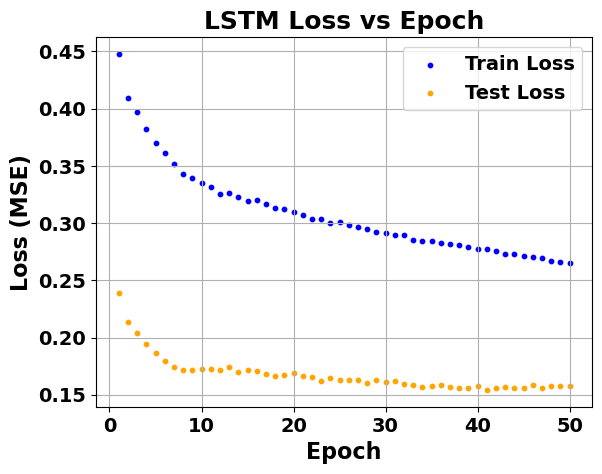

In [28]:
plt.scatter (loss_ep['epoch'], loss_ep['train_loss'], label='Train Loss', color='blue', s=10)
plt.scatter (loss_ep['epoch'], loss_ep['val_loss'], label='Test Loss', color='orange', s=10)
plt.title('LSTM Loss vs Epoch') 
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
#plt.yscale('log')   
plt.legend(fontsize=14)
plt.grid(True)
plt.savefig(os.path.join(loss_path, 'lstm_loss_vs_epoch.png'))
plt.show()


Step 4: Evaluate the model 

In [29]:
from evaluation.lstm.eval_lstm import evaluate_model
model_path = config['weight_paths']['lstm_model']
evaluate_model(model_path, config, device)

Metrics saved to C:/02_AtmPhy_ML/S4_AQ_PINN/evaluation/lstm/lstm_metrics.csv: 
  Parameter       MAE      RMSE        R2
0        CO  0.298871  0.412228  0.803277
1       NOx  0.238255  0.317761  0.869664
2       NO2  0.345857  0.448279  0.801735

Predictions saved to C:/02_AtmPhy_ML/S4_AQ_PINN/evaluation/lstm/lstm_predictions.csv: 
   CO_actual  NOx_actual  NO2_actual  CO_predicted  NOx_predicted  \
0   0.587902    1.442993    3.396049      0.583031       1.240941   
1   1.212887    1.768163    3.571203      1.320840       2.084563   
2   1.282330    1.680804    3.352260      1.486376       2.341726   
3   1.212887    1.525499    3.461731      1.376519       2.282389   
4   0.935116    1.506086    3.396049      1.016420       1.867313   

   NO2_predicted  
0       1.629076  
1       1.935722  
2       1.973573  
3       1.880576  
4       1.714930  


Step 5: Visualize


5.1 Correlation between true and predicted values

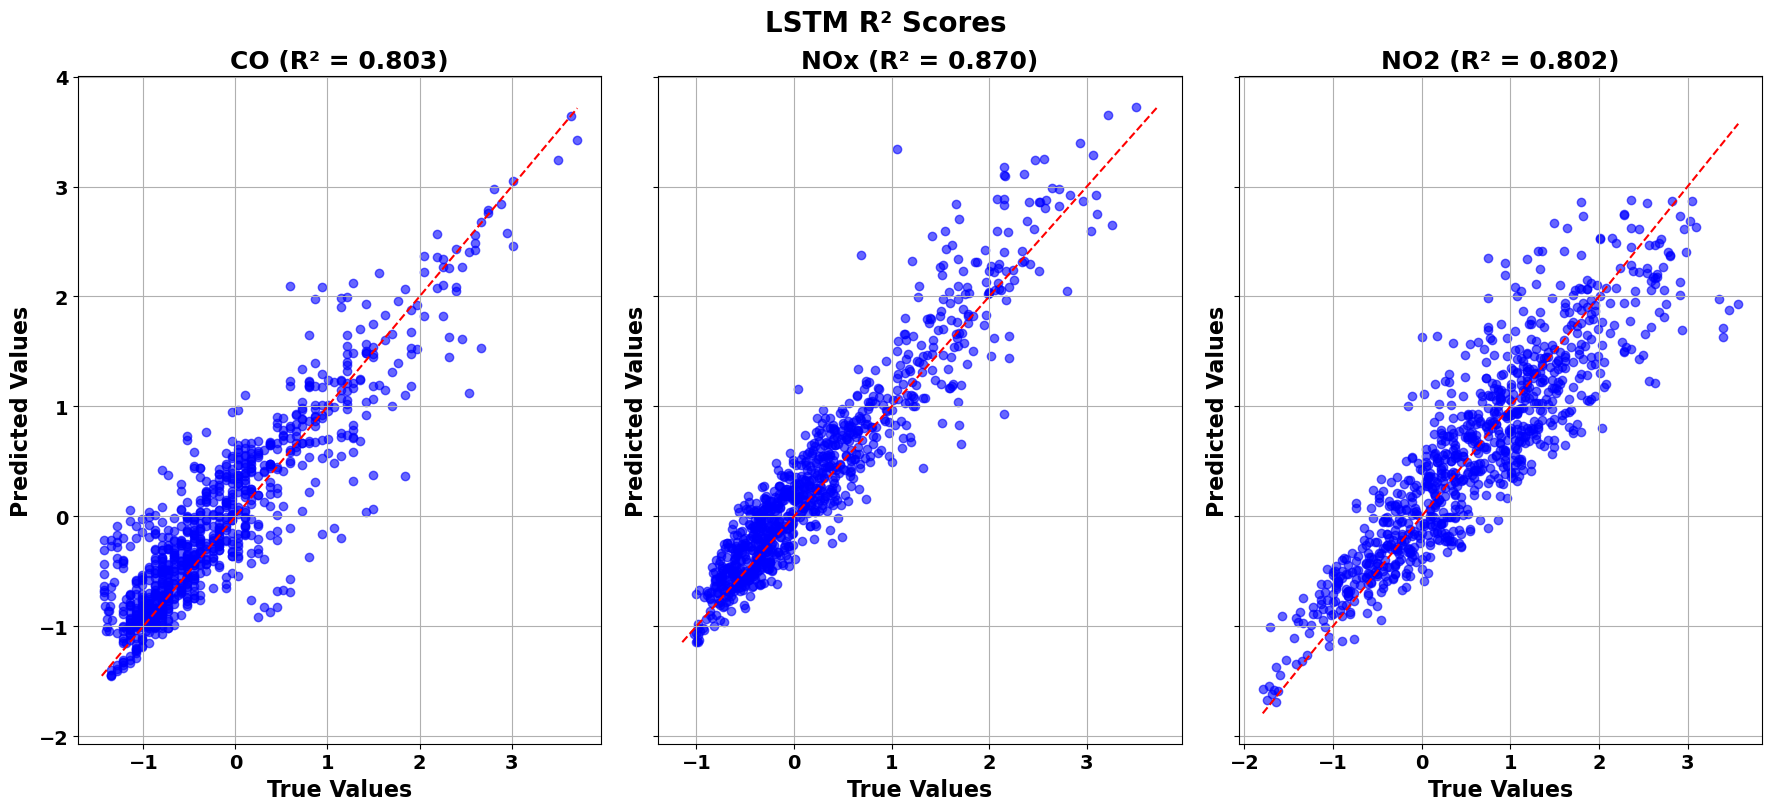

In [30]:
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

df_path = config['evaluation']['predictions_path']['lstm_predictions']
df = pd.read_csv(os.path.join(df_path, 'lstm_predictions.csv'))
true_df = df[[col for col in df.columns if 'actual' in col]]
pred_df = df[[col for col in df.columns if 'predicted' in col]]
outpath = config['evaluation']['predictions_path']['lstm_predictions']

# Assuming true_df and pred_df are pandas DataFrames containing columns like:
# true_df columns: ['CO_actual', 'NOx_actual', 'NO2_actual']
# pred_df columns: ['CO_predicted', 'NOx_predicted', 'NO2_predicted']

param_actual = ['CO_actual', 'NOx_actual', 'NO2_actual']
param_pred = ['CO_predicted', 'NOx_predicted', 'NO2_predicted']
param_names = ['CO', 'NOx', 'NO2']

fig, axes = plt.subplots(1, 3, figsize=(18, 8), sharey=True)
for i, ax in enumerate(axes):
    true_vals = true_df[param_actual[i]]
    pred_vals = pred_df[param_pred[i]]

    ax.scatter(true_vals, pred_vals, color='blue', alpha=0.6)
    min_val = min(true_vals.min(), pred_vals.min())
    max_val = max(true_vals.max(), pred_vals.max())
    ax.plot([min_val, max_val], [min_val, max_val], 'r--')  

    r2 = r2_score(true_vals, pred_vals)
    ax.set_title(f"{param_names[i]} (R² = {r2:.3f})")
    ax.set_xlabel('True Values')
    ax.set_ylabel('Predicted Values')
    ax.grid(True)

plt.tight_layout()
plt.suptitle('LSTM R² Scores', y=1.02)
plt.savefig(os.path.join(outpath, 'lstm_true_vs_pred_r2.png'))
plt.show()



5.2 Residuals and their distribution

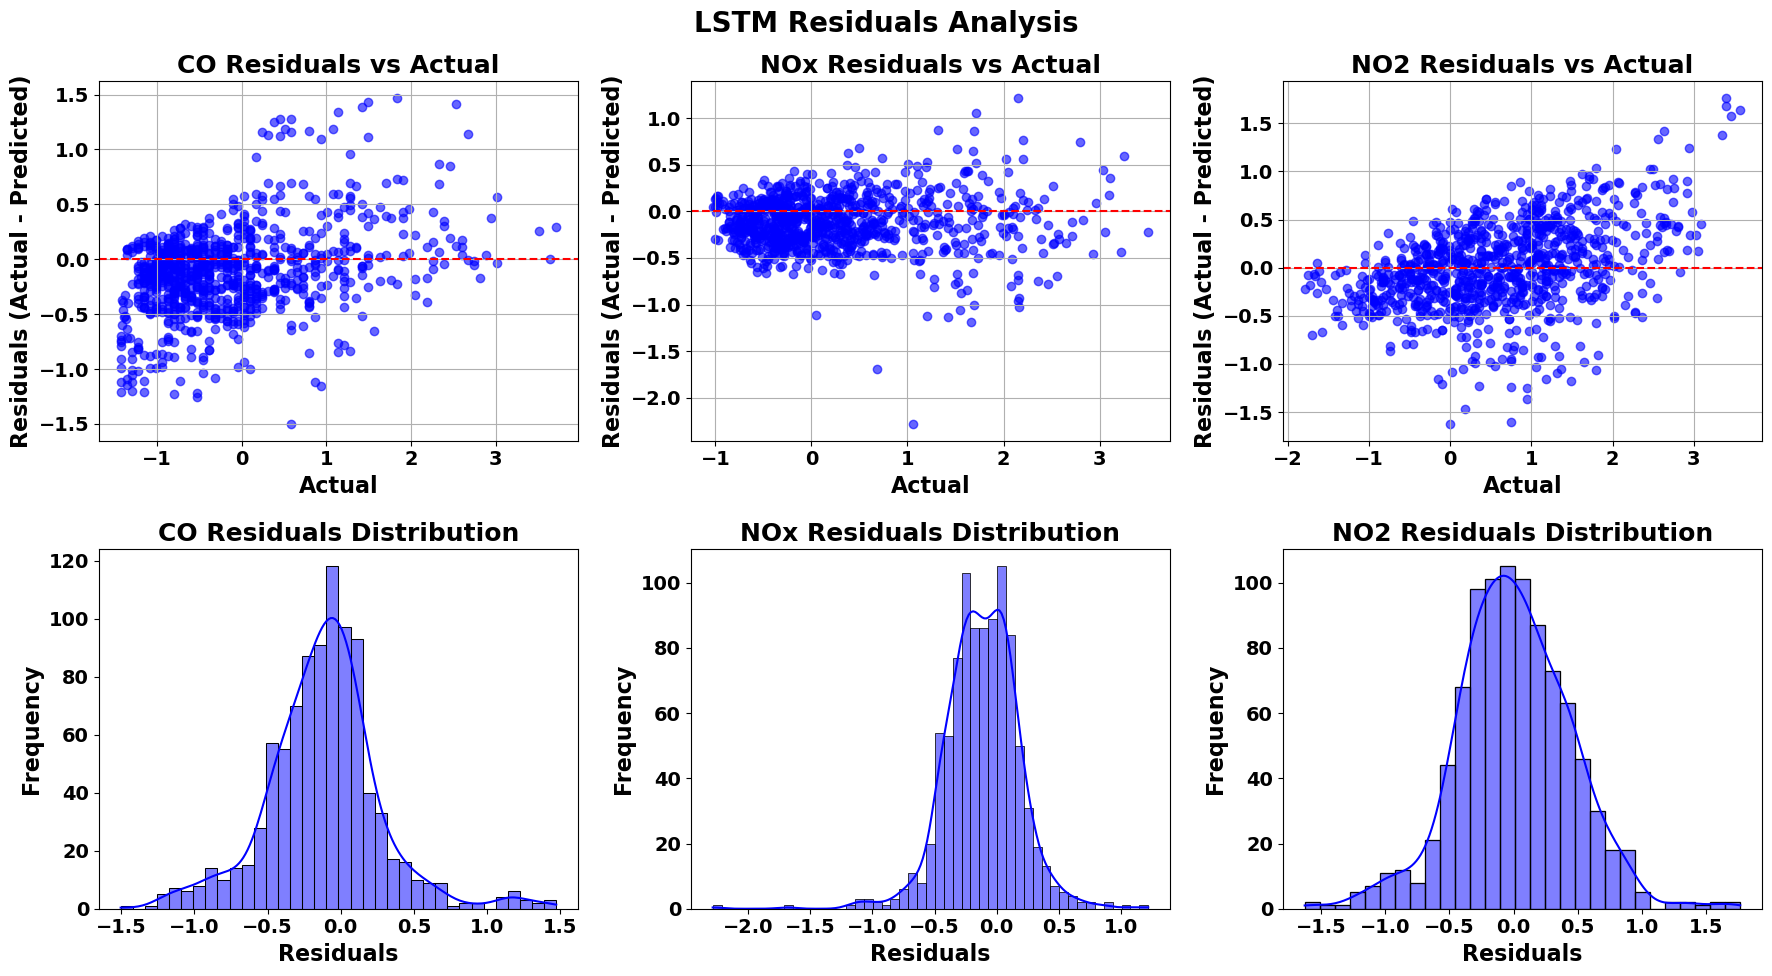

In [31]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for i in range(3):
    # Residuals = actual - predicted
    residuals = true_df[param_actual[i]] - pred_df[param_pred[i]]

    # Residual plot (residuals vs actual)
    axes[0, i].scatter(true_df[param_actual[i]], residuals, color='blue', alpha=0.6)
    axes[0, i].axhline(0, color='red', linestyle='--')
    axes[0, i].set_xlabel('Actual')
    axes[0, i].set_ylabel('Residuals (Actual - Predicted)')
    axes[0, i].set_title(f'{param_names[i]} Residuals vs Actual')
    axes[0, i].grid(True)

    # Residual distribution (Histogram + KDE)
    sns.histplot(residuals, kde=True, ax=axes[1, i], color='blue')
    axes[1, i].set_xlabel('Residuals')
    axes[1, i].set_ylabel('Frequency')
    axes[1, i].set_title(f'{param_names[i]} Residuals Distribution')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.suptitle('LSTM Residuals Analysis')

plt.savefig(os.path.join(outpath, 'lstm_residuals_analysis.png'))
plt.show()

5.3 Temporal dynamics

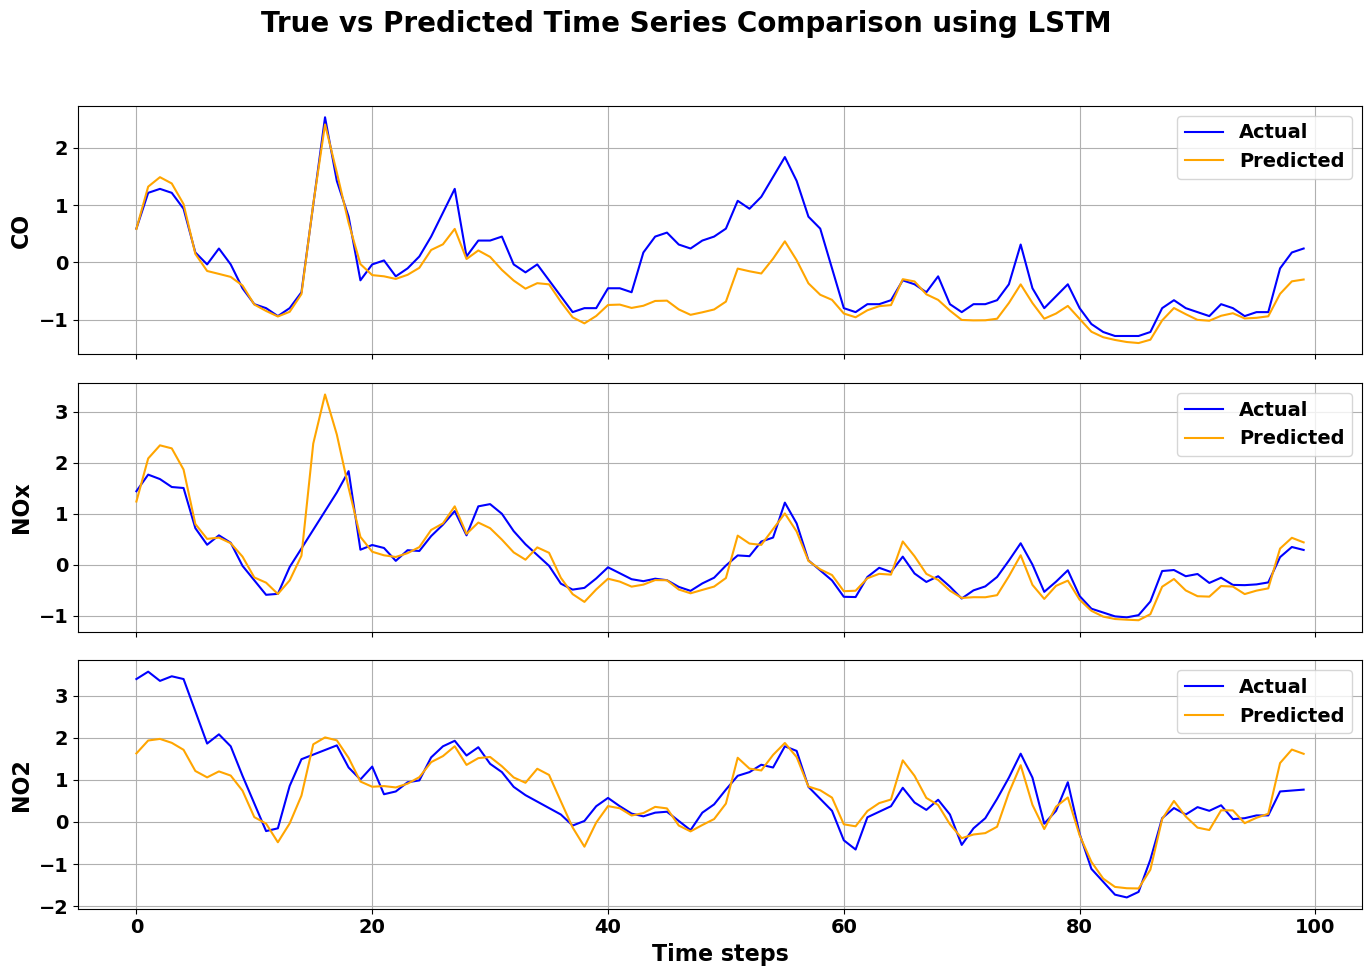

In [32]:
# Select subset time window for clarity, e.g., first 100 samples
window = 100
time_axis = range(window)  # or df['datetime'][:window] if you have timestamps

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

params = ['CO', 'NOx', 'NO2']

for i, param in enumerate(params):
    axes[i].plot(time_axis, df[f"{param}_actual"][:window], label='Actual', color='blue')
    axes[i].plot(time_axis, df[f"{param}_predicted"][:window], label='Predicted', color='orange')
    axes[i].set_ylabel(param)
    axes[i].legend()
    axes[i].grid(True)

axes[-1].set_xlabel('Time steps')

plt.suptitle('True vs Predicted Time Series Comparison using LSTM')
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig(os.path.join(outpath, 'lstm_time_series_comparison.png'))
plt.show()

5.4 Correlation heatmap between parameters

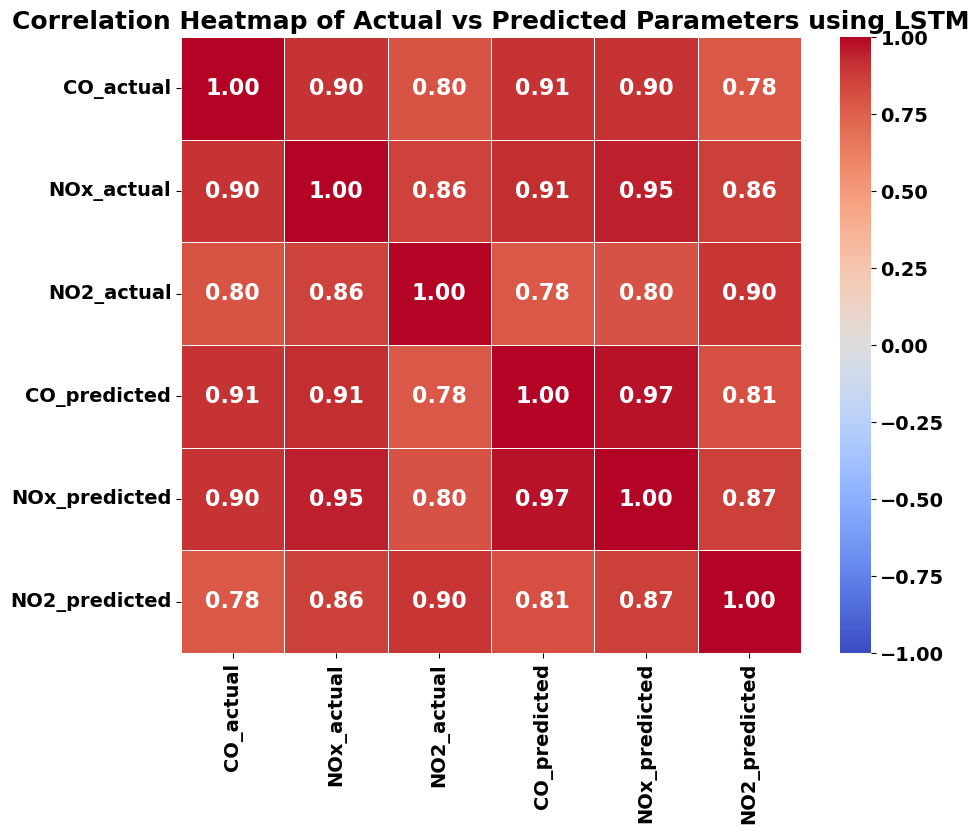

In [33]:
combined_df = df[param_actual + param_pred]

# Compute correlation matrix
corr_matrix = combined_df.corr()

# Plot heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, vmin=-1, vmax=1)
plt.title('Correlation Heatmap of Actual vs Predicted Parameters using LSTM')
plt.savefig(os.path.join(outpath, 'lstm_correlation_heatmap.png'))
plt.show()